<a href="https://colab.research.google.com/github/rheevinenghog-creator/Enghog_ml_activity_02.ipynb/blob/main/Enghog_Rheevin_KNN_Activity.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification, make_regression
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.metrics import accuracy_score, mean_squared_error, r2_score

np.random.seed(42)

In [ ]:
X_clf, y_clf = make_classification(
    n_samples=200, n_features=2, n_informative=2, n_redundant=0,
    n_clusters_per_class=1, weights=[0.5, 0.5], random_state=42
)

X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X_clf, y_clf, test_size=0.3, random_state=42
)

k_clf = 3
clf_model = KNeighborsClassifier(n_neighbors=k_clf)
clf_model.fit(X_train_clf, y_train_clf)

y_pred_clf = clf_model.predict(X_test_clf)
acc = accuracy_score(y_test_clf, y_pred_clf)
print(f"KNN Classifier (k={k_clf}) Accuracy: {acc:.4f}")

KNN Classifier (k=3) Accuracy: 0.8667


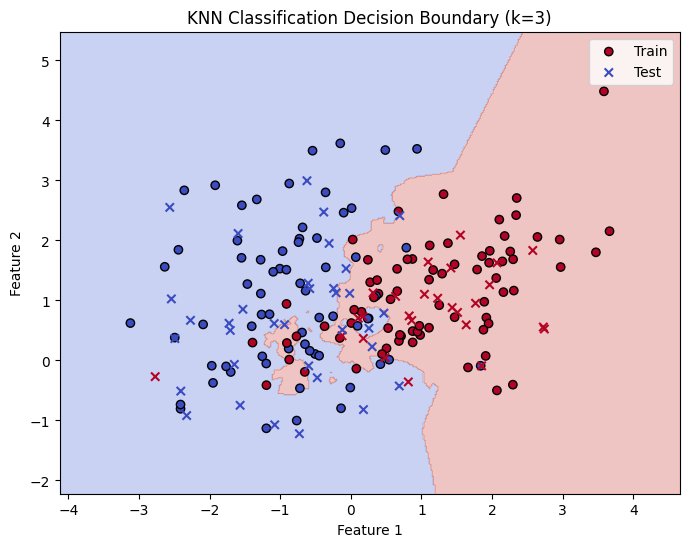

In [ ]:
x_min, x_max = X_clf[:, 0].min() - 1, X_clf[:, 0].max() + 1
y_min, y_max = X_clf[:, 1].min() - 1, X_clf[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))
Z = clf_model.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
plt.scatter(X_train_clf[:, 0], X_train_clf[:, 1], c=y_train_clf, marker='o', label='Train', cmap='coolwarm', edgecolor='k')
plt.scatter(X_test_clf[:, 0], X_test_clf[:, 1], c=y_test_clf, marker='x', label='Test', cmap='coolwarm')
plt.title(f"KNN Classification Decision Boundary (k={k_clf})")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.show()

In [ ]:
X_reg, y_reg = make_regression(n_samples=100, n_features=1, noise=15.0, random_state=42)

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.3, random_state=42
)

sort_idx = np.argsort(X_test_reg.squeeze())
X_test_reg_sorted = X_test_reg[sort_idx]
y_test_reg_sorted = y_test_reg[sort_idx]

k_reg = 5
reg_model = KNeighborsRegressor(n_neighbors=k_reg)
reg_model.fit(X_train_reg, y_train_reg)

y_pred_reg_sorted = reg_model.predict(X_test_reg_sorted)
mse = mean_squared_error(y_test_reg_sorted, y_pred_reg_sorted)
r2 = r2_score(y_test_reg_sorted, y_pred_reg_sorted)
print(f"KNN Regressor (k={k_reg}) MSE: {mse:.4f}, R2 Score: {r2:.4f}")

KNN Regressor (k=5) MSE: 236.1232, R2 Score: 0.8783


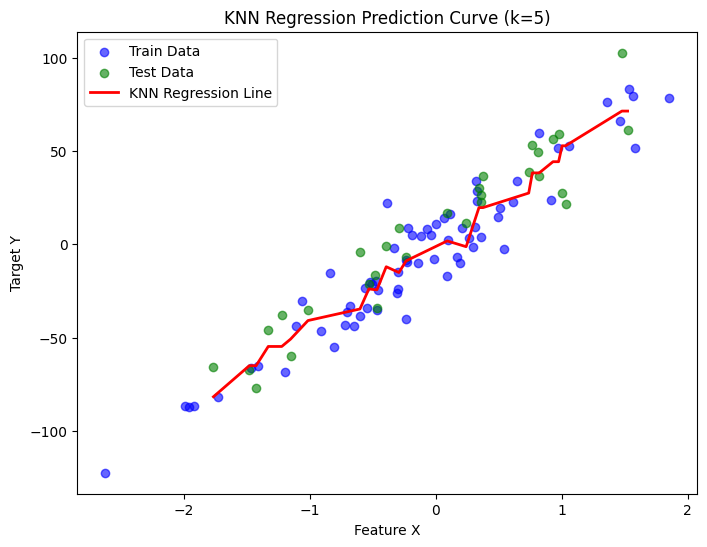

In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter(X_train_reg, y_train_reg, color='blue', label='Train Data', alpha=0.6)
plt.scatter(X_test_reg_sorted, y_test_reg_sorted, color='green', label='Test Data', alpha=0.6)
plt.plot(X_test_reg_sorted, y_pred_reg_sorted, color='red', linewidth=2, label='KNN Regression Line')
plt.title(f"KNN Regression Prediction Curve (k={k_reg})")
plt.xlabel("Feature X")
plt.ylabel("Target Y")
plt.legend()
plt.show()

In [ ]:
from sklearn.neighbors import NearestNeighbors

query_point = np.array([[0.0, 0.0]])

for k_neighbors in [3, 5, 9]:
    nn = NearestNeighbors(n_neighbors=k_neighbors)
    nn.fit(X_train_clf)
    distances, indices = nn.kneighbors(query_point)
    print(f"\nNeighbors for K = {k_neighbors}")
    print("Indices of nearest points:", indices)
    print("Distances to nearest points:", distances)


Neighbors for K = 3
Indices of nearest points: [[84 63 13]]
Distances to nearest points: [[0.15839705 0.40518394 0.42338476]]

Neighbors for K = 5
Indices of nearest points: [[ 84  63  13  86 105]]
Distances to nearest points: [[0.15839705 0.40518394 0.42338476 0.45290392 0.45434081]]

Neighbors for K = 9
Indices of nearest points: [[ 84  63  13  86 105  57  49  71  79]]
Distances to nearest points: [[0.15839705 0.40518394 0.42338476 0.45290392 0.45434081 0.45577436
  0.51773712 0.54191413 0.54347445]]


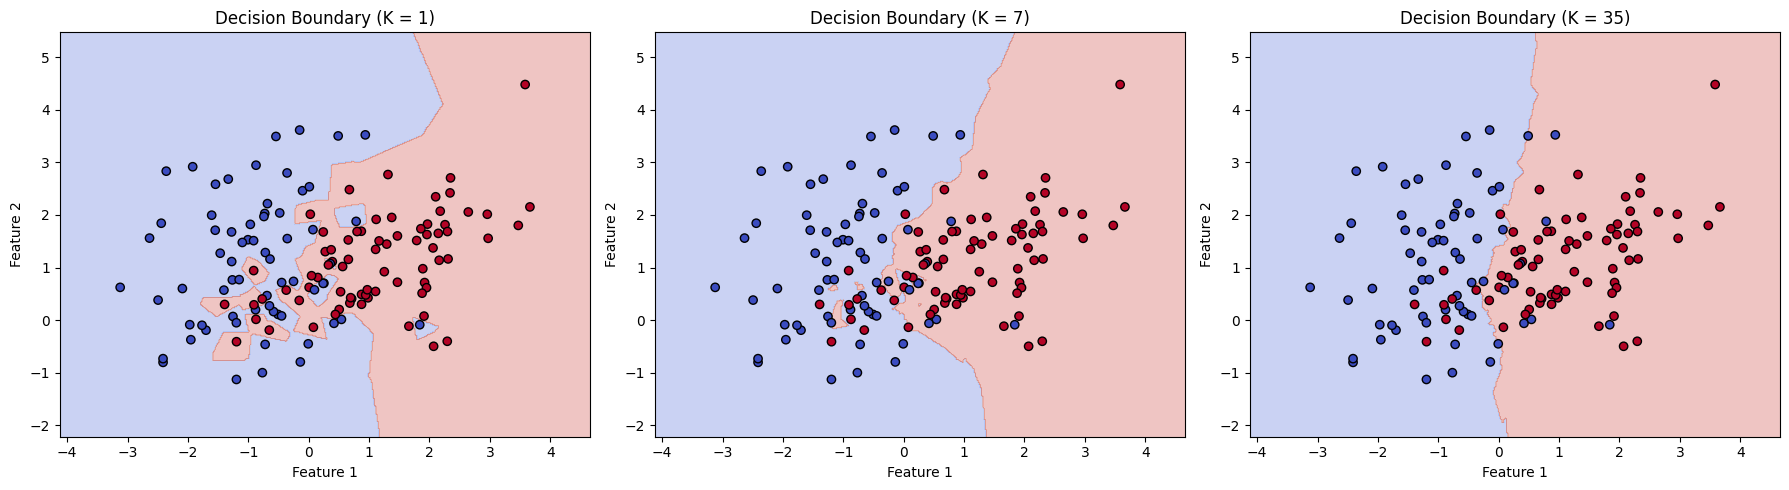

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, k in enumerate([1, 7, 35]):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_clf, y_train_clf)

    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    axes[i].contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
    axes[i].scatter(X_train_clf[:, 0], X_train_clf[:, 1], c=y_train_clf, marker='o', cmap='coolwarm', edgecolor='k')
    axes[i].set_title(f"Decision Boundary (K = {k})")
    axes[i].set_xlabel("Feature 1")
    axes[i].set_ylabel("Feature 2")

plt.tight_layout()
plt.show()

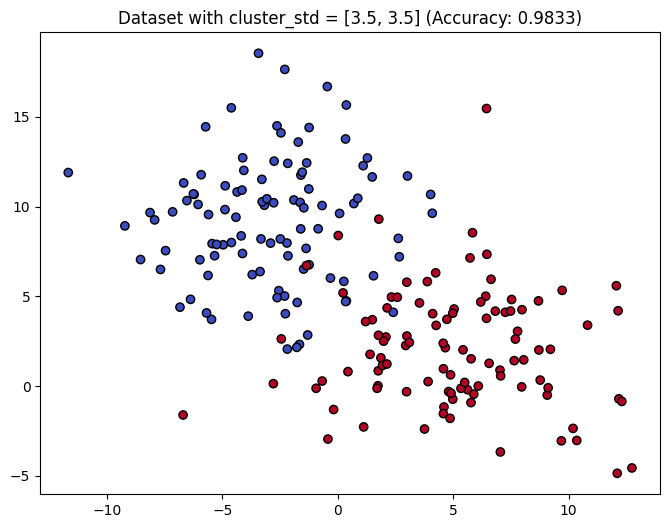

In [ ]:
from sklearn.datasets import make_blobs

X_var, y_var = make_blobs(n_samples=200, centers=2, cluster_std=3.5, random_state=42)
X_train_var, X_test_var, y_train_var, y_test_var = train_test_split(X_var, y_var, test_size=0.3, random_state=42)

model_var = KNeighborsClassifier(n_neighbors=5)
model_var.fit(X_train_var, y_train_var)
acc_var = accuracy_score(y_test_var, model_var.predict(X_test_var))

plt.figure(figsize=(8, 6))
plt.scatter(X_var[:, 0], X_var[:, 1], c=y_var, cmap='coolwarm', edgecolor='k')
plt.title(f"Dataset with cluster_std = [3.5, 3.5] (Accuracy: {acc_var:.4f})")
plt.show()

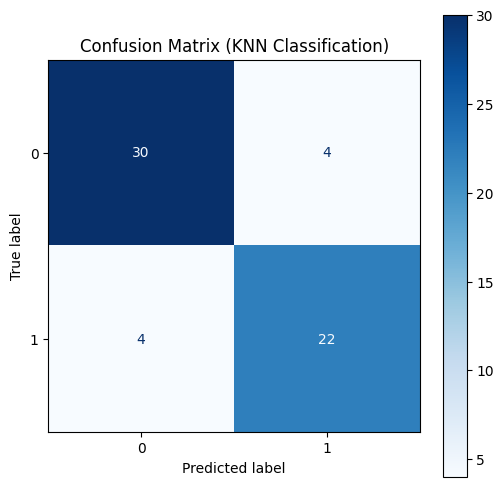

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test_clf, y_pred_clf)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=clf_model.classes_)

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, cmap='Blues')
plt.title("Confusion Matrix (KNN Classification)")
plt.show()

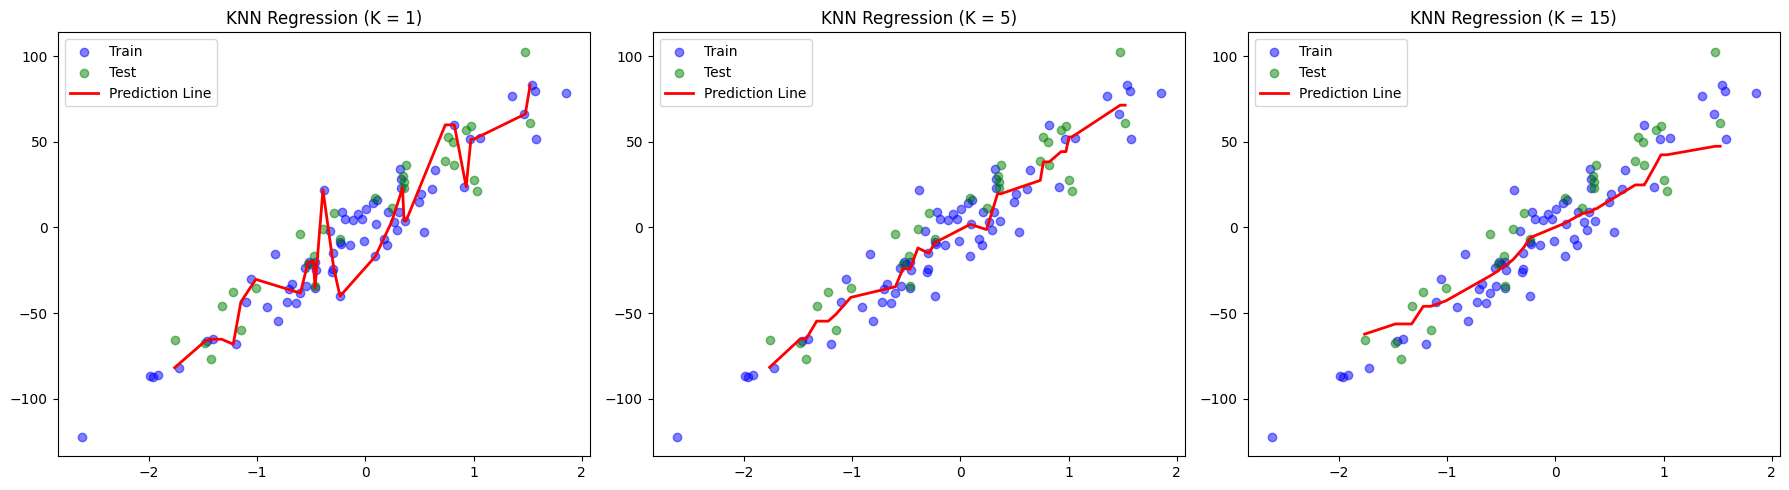

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, k in enumerate([1, 5, 15]):
    model = KNeighborsRegressor(n_neighbors=k)
    model.fit(X_train_reg, y_train_reg)
    y_pred = model.predict(X_test_reg_sorted)

    axes[i].scatter(X_train_reg, y_train_reg, color='blue', alpha=0.5, label='Train')
    axes[i].scatter(X_test_reg_sorted, y_test_reg_sorted, color='green', alpha=0.5, label='Test')
    axes[i].plot(X_test_reg_sorted, y_pred, color='red', linewidth=2, label='Prediction Line')
    axes[i].set_title(f"KNN Regression (K = {k})")
    axes[i].legend()

plt.tight_layout()
plt.show()